In [1]:
import pandas as pd                                      # For data handling
import numpy as np                                       # For numerical calculations
import matplotlib.pyplot as plt                           # For plotting
import seaborn as sns                                    # For data visualization

from sklearn.model_selection import train_test_split     # For splitting data
from sklearn.preprocessing import StandardScaler         # For feature scaling
from sklearn.neighbors import KNeighborsClassifier       # For KNN algorithm
from sklearn.metrics import confusion_matrix              # For confusion matrix
from sklearn.metrics import accuracy_score                # For accuracy
from sklearn.metrics import precision_score               # For precision
from sklearn.metrics import recall_score                  # For recall

In [2]:
df = pd.read_csv(r"C:\Users\prath\Desktop\SEM 7\LP3\ML\Datasets\diabetes.csv")                         # Load the diabetes dataset

print(df.head())                                         # Display first 5 rows
print(df.shape)                                          # Display number of rows and columns

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
(768, 9)


In [3]:
print(df.info())                                         # Display dataset information

print(df.isnull().sum())                                 # Check missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [4]:
X = df.drop("Outcome", axis=1)                           # Select input features
y = df["Outcome"]                                        # Select target variable

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)                                                        # Split data into 80% training and 20% testing
scaler = StandardScaler()                                # Create standard scaler

X_train = scaler.fit_transform(X_train)                  # Scale training data
X_test = scaler.transform(X_test)                        # Scale testing data

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)                 # Create KNN model with K=5

knn.fit(X_train, y_train)                                # Train the KNN model

y_pred = knn.predict(X_test)                             # Predict results for test data

In [8]:
cm = confusion_matrix(y_test, y_pred)                    # Calculate confusion matrix

print("Confusion Matrix:")
print(cm)                                                # Display confusion matrix

Confusion Matrix:
[[80 20]
 [26 28]]


In [9]:
accuracy = accuracy_score(y_test, y_pred)                # Calculate accuracy

print("Accuracy:", accuracy)                             # Display accuracy

Accuracy: 0.7012987012987013


In [10]:
error_rate = 1 - accuracy                                # Calculate error rate

print("Error Rate:", error_rate)                         # Display error rate

Error Rate: 0.2987012987012987


In [11]:
precision = precision_score(y_test, y_pred)              # Calculate precision

print("Precision:", precision)                           # Display precision

Precision: 0.5833333333333334


In [12]:
recall = recall_score(y_test, y_pred)                    # Calculate recall

print("Recall:", recall)                                 # Display recall

Recall: 0.5185185185185185


In [13]:
print("----- KNN Performance -----")                       # Display heading
print("Accuracy :", accuracy)                            # Display accuracy
print("Error Rate :", error_rate)                        # Display error rate
print("Precision :", precision)                          # Display precision
print("Recall :", recall)                                # Display recall

----- KNN Performance -----
Accuracy : 0.7012987012987013
Error Rate : 0.2987012987012987
Precision : 0.5833333333333334
Recall : 0.5185185185185185


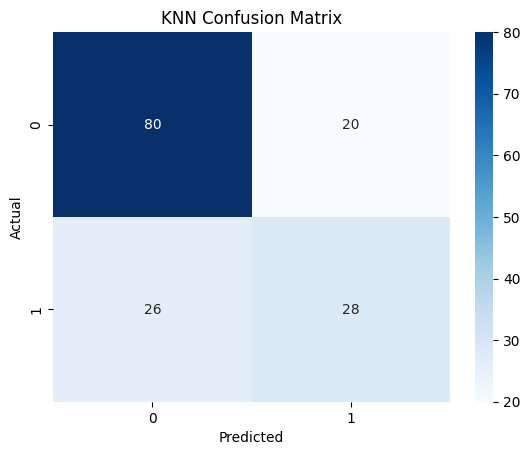

In [14]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")       # Display confusion matrix as heatmap

plt.xlabel("Predicted")                                  # Label x-axis
plt.ylabel("Actual")                                     # Label y-axis
plt.title("KNN Confusion Matrix")                        # Add title
plt.show()                                               # Display the graph

In [ ]:
'''What type of machine learning is KNN?  
KNN is a supervised machine learning algorithm.

Is this classification or regression?  
This practical uses classification because we predict whether a person has diabetes or not.

. What are the two classes in this dataset?  
0 = No Diabetes and 1 = Diabetes.

What is the target variable?  
Outcome is the target variable.

. What is KNN?  
K-Nearest Neighbors classifies a new data point based on the classes of its nearest neighboring points.

K mean in KNN?  
K represents the number of nearest neighbors considered for prediction.

K did you use?  
K = 5.

KNN make a prediction?  
It finds the K nearest data points and assigns the class that gets the majority vote.

Why do we use StandardScaler?  
Because KNN uses distance, so features with larger values could otherwise dominate the calculation.

StandardScaler do?  
It scales the features to have approximately mean 0 and standard deviation 1.



